In [1]:
import matplotlib.pyplot as plt
import pylab
import os
import numpy as np
from scipy.optimize import curve_fit
import pandas as pd
from collections import Counter
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import MultipleLocator

stripE
stripF1
stripA2


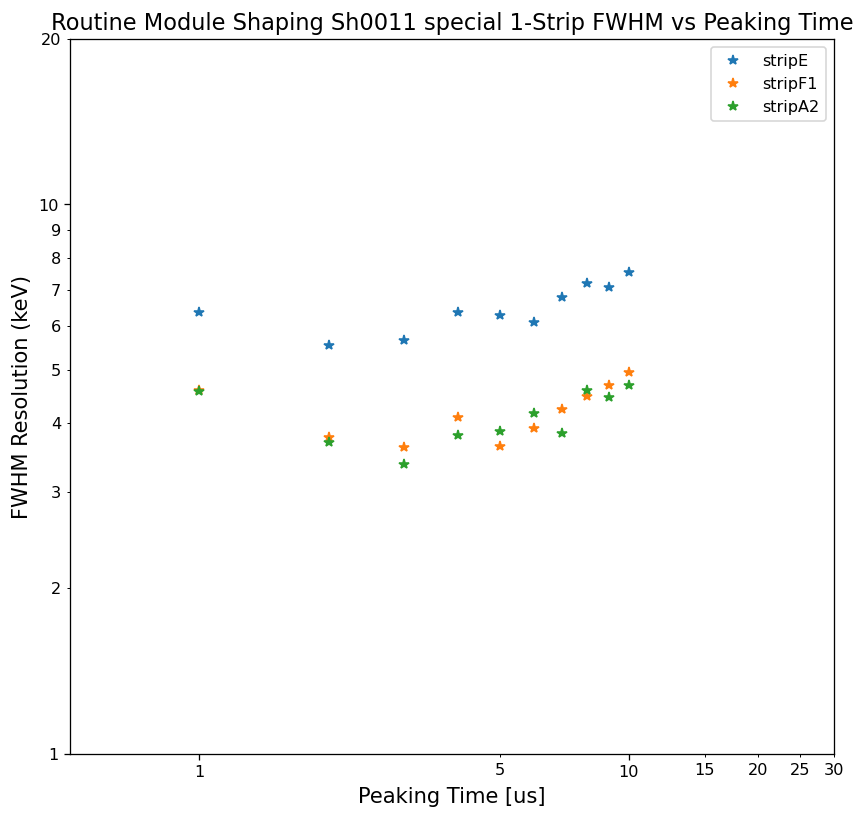

In [3]:
#Find file and store values

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V"
file_path = os.path.join(prename)

det = 136
datfile = os.path.join(prename,'summary_KYfit.dat')
df = pd.read_csv(datfile, sep='\t', header=None)
nlines = len(df) #number of lines in the file
strip_list = list(set(df.head(nlines)[:][1])) #Individual strip names
nstrips = len(strip_list)

#What's the best way to do this? Associate each point with a strip/plot, something robust
#Check each line for the Strip name and put the numbers in the associated FWHM and errors array

#Below, use the .head()[column][row] function to pull specific values.
#[0] detector number, [1] strip letter, [2] PT in ns, [3] FWHM in keV, [4] error in FWHM
#print(df.head(nlines)[:][1])
#print(strip_list)

f1 = plt.figure(figsize=(8.5,8),dpi=116)
ax1 = plt.gca()

ax1.semilogx()
ax1.semilogy()
ax1.set_xlabel("Peaking Time [us]",fontsize=13)
ax1.set_ylabel("FWHM Resolution (keV)",fontsize=13)
ax1.set_title(f'Routine Module Shaping Sh0011 special 1-Strip FWHM vs Peaking Time',fontsize=14)
ax1.set_ylim(1,20)
ax1.set_xlim(0.5,30)
ax1.xaxis.set_major_formatter(ScalarFormatter())
ax1.xaxis.set_minor_formatter(ScalarFormatter())
ax1.xaxis.set_minor_locator(MultipleLocator(5))
ax1.xaxis.set_major_formatter('{x:.0f}')
ax1.xaxis.set_minor_formatter('{x:.0f}')

ax1.yaxis.set_major_formatter(ScalarFormatter())
ax1.yaxis.set_minor_formatter(ScalarFormatter())
ax1.yaxis.set_major_formatter('{x:.0f}')
ax1.yaxis.set_minor_formatter('{x:.0f}')

tarray = [0]*5 #Dat file structure has 5 lines

#Go line by line through the file, check the strip name, associate it with strip, right now I just want the FWHM and PT values!

for strp in strip_list:
    #Need to open this to be read each time!
    pltfile = open(datfile, "r")
    print(strp)
    FWHM = []
    PT = []
    #Go through the entire file
    for i, x in enumerate(pltfile):
        tarray = x.strip().split('\t')
        if(tarray[1] == strp):
            #print(f'PT: {tarray[2]} and FWHM {tarray[3]}')
            PT.append(float(tarray[2])/1000)
            FWHM.append(float(tarray[3]))
    ax1.plot(PT,FWHM,'*',label=strp)
ax1.legend()


savename = os.path.join(file_path,f"{det}_Spectra.png")
plt.savefig(savename) #Save the file
plt.show()

stripE
[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
[6.37, 5.55, 5.66, 6.37, 6.28, 6.1, 6.78, 7.18, 7.06, 7.53]
[-4.25218437e-33 -7.67414546e-33 -2.52797718e-13]
Af = -2.52797717888892e-13
Ileak = -3.984882880761641e-10


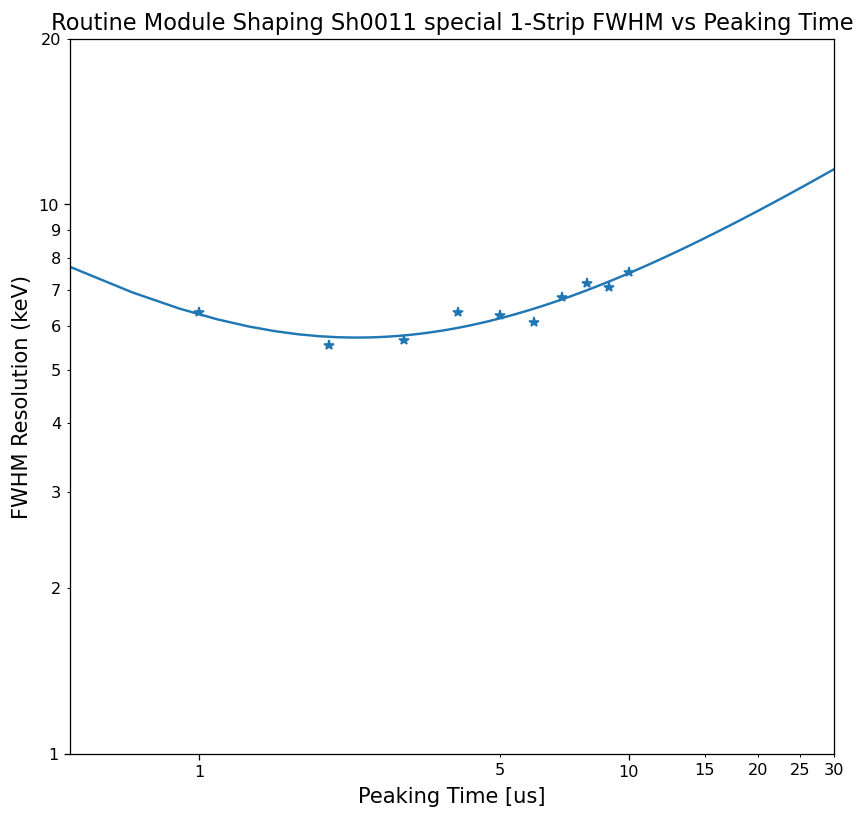

In [4]:
f1 = plt.figure(figsize=(8.5,8),dpi=116)
ax1 = plt.gca()

ax1.semilogx()
ax1.semilogy()
ax1.set_xlabel("Peaking Time [us]",fontsize=13)
ax1.set_ylabel("FWHM Resolution (keV)",fontsize=13)
ax1.set_title(f'Routine Module Shaping Sh0011 special 1-Strip FWHM vs Peaking Time',fontsize=14)
ax1.set_ylim(1,20)
ax1.set_xlim(0.5,30)
ax1.xaxis.set_major_formatter(ScalarFormatter())
ax1.xaxis.set_minor_formatter(ScalarFormatter())
ax1.xaxis.set_minor_locator(MultipleLocator(5))
ax1.xaxis.set_major_formatter('{x:.0f}')
ax1.xaxis.set_minor_formatter('{x:.0f}')

ax1.yaxis.set_major_formatter(ScalarFormatter())
ax1.yaxis.set_minor_formatter(ScalarFormatter())
ax1.yaxis.set_major_formatter('{x:.0f}')
ax1.yaxis.set_minor_formatter('{x:.0f}')


Cstrip = 38 #pF 8-strip is ~38 pF
Cothers = 30 #CFET = 10 pF, Cstrap + Cint = 20 pF
Ctot = (Cstrip + Cothers)*10**-12

q = 1.6e-19 #electron charge
k = 1.38e-23 #Bolzmann constant
eps = 3.6 #ionization energy of silicon
Rp = 100e6 #parallel resistance of preamp
gm = 18e-3 #transconductanct in FET ?Differrent than the paper says?
Bita = 1 #Not sure what this is yet
factor = (2.355*eps*1e-3/q); #Factor from ENC to FWHM
pi = 3.14159

T_Celsius = -42
T = (T_Celsius + 273)

strp = "stripE"
pltfile = open(datfile, "r")
print(strp)
FWHM = []
PT = []

    #Go through the entire file
for i, x in enumerate(pltfile):
    tarray = x.strip().split('\t')
    if(tarray[1] == strp):
        #print(f'PT: {tarray[2]} and FWHM {tarray[3]}')
        PT.append(float(tarray[2])/1000)
        FWHM.append(float(tarray[3]))

print(PT)
print(FWHM)
ax1.plot(PT,FWHM,'*',label=strp)

def eres_spectra(x, term_1, term_2, term_3):
    return factor*np.sqrt( abs(  term_1*(0.5e-6 + x/3) + term_2/x + 2*pi*term_3*Ctot**2*0.5*1.38) )

x_fitpars, x_mat = curve_fit(eres_spectra, PT, FWHM, p0=[1e-33, 15, 0.1e-13])
xvals = np.arange(0.5,30,0.2)

print(x_fitpars)

print(f'Af = {x_fitpars[2]}')
print(f'Ileak = {(x_fitpars[0]-(4*k*T/Rp))/(2*q)}')

fit_vals = eres_spectra(xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])
ax1.plot(xvals,fit_vals,color='tab:blue')


stripE
[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
[6.37, 5.55, 5.66, 6.37, 6.28, 6.1, 6.78, 7.18, 7.06, 7.53]


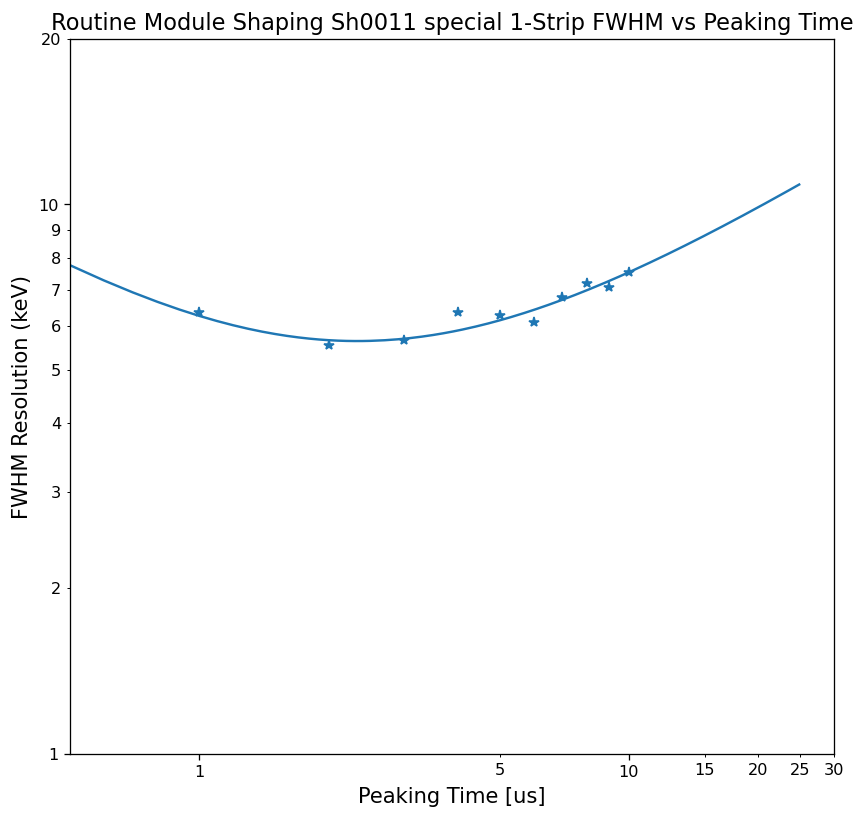

In [5]:
f1 = plt.figure(figsize=(8.5,8),dpi=116)
ax1 = plt.gca()

ax1.semilogx()
ax1.semilogy()
ax1.set_xlabel("Peaking Time [us]",fontsize=13)
ax1.set_ylabel("FWHM Resolution (keV)",fontsize=13)
ax1.set_title(f'Routine Module Shaping Sh0011 special 1-Strip FWHM vs Peaking Time',fontsize=14)
ax1.set_ylim(1,20)
ax1.set_xlim(0.5,30)
ax1.xaxis.set_major_formatter(ScalarFormatter())
ax1.xaxis.set_minor_formatter(ScalarFormatter())
ax1.xaxis.set_minor_locator(MultipleLocator(5))
ax1.xaxis.set_major_formatter('{x:.0f}')
ax1.xaxis.set_minor_formatter('{x:.0f}')

ax1.yaxis.set_major_formatter(ScalarFormatter())
ax1.yaxis.set_minor_formatter(ScalarFormatter())
ax1.yaxis.set_major_formatter('{x:.0f}')
ax1.yaxis.set_minor_formatter('{x:.0f}')


Cstrip = 38 #pF 8-strip is ~38 pF
Cothers = 30 #CFET = 10 pF, Cstrap + Cint = 20 pF
Ctot = (Cstrip + Cothers)*10**-12

q = 1.6e-19 #electron charge
k = 1.38e-23 #Bolzmann constant
eps = 3.6 #ionization energy of silicon
Rp = 100e6 #parallel resistance of preamp
gm = 18e-3 #transconductanct in FET ?Differrent than the paper says?
Bita = 1 #Not sure what this is yet
factor = (2.355*eps*1e-3/q); #Factor from ENC to FWHM
pi = 3.14159

T_Celsius = -42
T = (T_Celsius + 273)

strp = "stripE"
pltfile = open(datfile, "r")
print(strp)
FWHM = []
PT = []

    #Go through the entire file
for i, x in enumerate(pltfile):
    tarray = x.strip().split('\t')
    if(tarray[1] == strp):
        #print(f'PT: {tarray[2]} and FWHM {tarray[3]}')
        PT.append(float(tarray[2])/1000)
        FWHM.append(float(tarray[3]))

print(PT)
print(FWHM)
ax1.plot(PT,FWHM,'*',label=strp)

PT_manual = np.arange(0.4, 25.0, 0.1)
PT_manual = PT_manual*10**-6
r = 1
Ileak = 13.7e-9
Cstrip = r*38
Af = 1.03e-13
Rs = 83

Ctot = (Cstrip + Cothers)*10**-12
enc = (2*q*Ileak + 4*k*T/Rp)*(0.5e-6 + PT_manual/3) + (4*k*T*Ctot**2*(Rs + Bita/gm))/PT_manual + 2*pi*Af*Ctot**2*0.5*1.38
FWHM_manual = factor*np.sqrt(enc)
ax1.plot(PT_manual*1e6,FWHM_manual,color='tab:blue')


stripF1
[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
[4.6, 3.77, 3.61, 4.1, 3.64, 3.91, 4.25, 4.48, 4.7, 4.96]


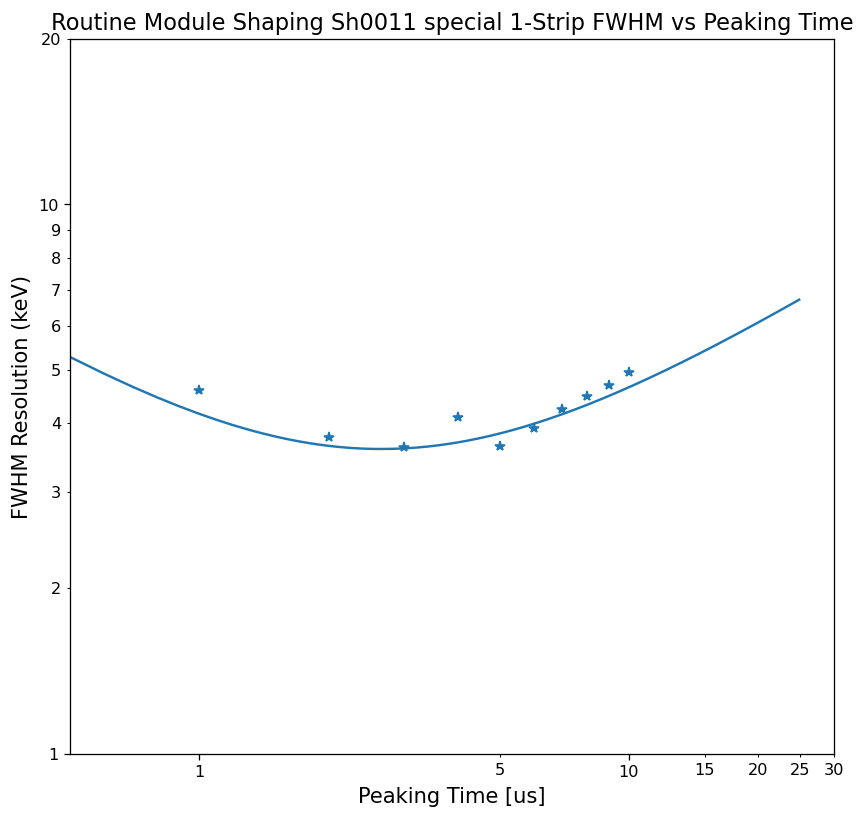

In [16]:
f1 = plt.figure(figsize=(8.5,8),dpi=116)
ax1 = plt.gca()

ax1.semilogx()
ax1.semilogy()
ax1.set_xlabel("Peaking Time [us]",fontsize=13)
ax1.set_ylabel("FWHM Resolution (keV)",fontsize=13)
ax1.set_title(f'Routine Module Shaping Sh0011 special 1-Strip FWHM vs Peaking Time',fontsize=14)
ax1.set_ylim(1,20)
ax1.set_xlim(0.5,30)
ax1.xaxis.set_major_formatter(ScalarFormatter())
ax1.xaxis.set_minor_formatter(ScalarFormatter())
ax1.xaxis.set_minor_locator(MultipleLocator(5))
ax1.xaxis.set_major_formatter('{x:.0f}')
ax1.xaxis.set_minor_formatter('{x:.0f}')

ax1.yaxis.set_major_formatter(ScalarFormatter())
ax1.yaxis.set_minor_formatter(ScalarFormatter())
ax1.yaxis.set_major_formatter('{x:.0f}')
ax1.yaxis.set_minor_formatter('{x:.0f}')


Cstrip = 38 #pF 8-strip is ~38 pF
Cothers = 30 #CFET = 10 pF, Cstrap + Cint = 20 pF
Ctot = (Cstrip + Cothers)*10**-12

q = 1.6e-19 #electron charge
k = 1.38e-23 #Bolzmann constant
eps = 3.6 #ionization energy of silicon
Rp = 100e6 #parallel resistance of preamp
gm = 18e-3 #transconductanct in FET ?Differrent than the paper says?
Bita = 1 #Not sure what this is yet
factor = (2.355*eps*1e-3/q); #Factor from ENC to FWHM
pi = 3.14159

T_Celsius = -42
T = (T_Celsius + 273)

strp = "stripF1"
pltfile = open(datfile, "r")
print(strp)
FWHM = []
PT = []

    #Go through the entire file
for i, x in enumerate(pltfile):
    tarray = x.strip().split('\t')
    if(tarray[1] == strp):
        #print(f'PT: {tarray[2]} and FWHM {tarray[3]}')
        PT.append(float(tarray[2])/1000)
        FWHM.append(float(tarray[3]))

print(PT)
print(FWHM)
ax1.plot(PT,FWHM,'*',label=strp)

PT_manual = np.arange(0.4, 25.0, 0.1)
PT_manual = PT_manual*10**-6
r = 0.4 #ratio of area of new strip to area of 8-strip

Ileak = 5e-9
Cstrip = r*38
Af = 0.75e-13
Rs = 100
Ctot = (Cstrip + Cothers)*10**-12

enc = (2*q*Ileak + 4*k*T/Rp)*(0.5e-6 + PT_manual/3) + (4*k*T*Ctot**2*(Rs + Bita/gm))/PT_manual + 2*pi*Af*Ctot**2*0.5*1.38
FWHM_manual = factor*np.sqrt(enc)
ax1.plot(PT_manual*1e6,FWHM_manual,color='tab:blue')
